# 04. Machine Learning Modeling & Benchmarking
การแบ่งข้อมูลแบบ Time-Based Split (80/20) และการทดสอบเปรียบเทียบโมเดล 5 ตัว (LogReg, RF, GBDT, XGBoost, LightGBM) บน 6 ตัวแปรเป้าหมาย

# PIPELINE

### 1. Data Integration and Alignment
- ทำการคัดกรองข้อมูลหุ้นส่งออก (Export) โดยตัด `AAI` และ `ITC` ออก คงเหลือหุ้น 8 ตัว
- ทำการคัดกรองข้อมูลหุ้นนำเข้า (Import) โดยตัด `COM7` และ `BGRIM` ออก คงเหลือหุ้น 8 ตัว
- คำนวณหาค่าเฉลี่ยรายวันของกลุ่มส่งออก (`Export_Avg`) และกลุ่มนำเข้า (`Import_Avg`)
- จัดเตรียมและรวมข้อมูลแกน X (ฟีเจอร์): `Brent`, `US_10Y`, `USD_THB`, `Volatility_to_Open`, `Yield_Curve_Slope` (TH_20Y - TH_10Y)
- จัดเตรียมและรวมข้อมูลแกน Y (เป้าหมาย): `Import_Avg`, `Export_Avg` และหุ้นรายตัวตัวแทน ได้แก่ `BH`, `BDMS` (กลุ่มส่งออก) และ `EGCO`, `BCP` (กลุ่มนำเข้า)
- ทำการคลีนข้อมูล จัดการค่าว่างแบบ Forward/Backward Fill และทำการ Aligned ข้อมูลให้อยู่บนอนุกรมเวลา (Date) เดียวกันทั้งหมด

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

# ตรวจสอบและโหลด baseline_pipeline_data.csv อัตโนมัติ (หากรันแบบแยกรันเดี่ยว)
if 'final_pipeline_df' not in globals():
    base_candidates = [
        Path('../data/03_processed/baseline_pipeline_data.csv'),
        Path('data/03_processed/baseline_pipeline_data.csv'),
        Path('./baseline_pipeline_data.csv')
    ]
    for p in base_candidates:
        if p.exists():
            final_pipeline_df = pd.read_csv(p)
            final_pipeline_df['Date'] = pd.to_datetime(final_pipeline_df['Date'])
            x_cols = ['Brent', 'US_10Y', 'USD_THB', 'Volatility_to_Open', 'Yield_Curve_Slope']
            y_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']
            X = final_pipeline_df[x_cols]
            Y = final_pipeline_df[y_cols]
            print(f"✓ โหลด baseline_pipeline_data.csv สำเร็จจาก: {p}")
            break

# หากยังไม่มีไฟล์ ให้ประมวลผลจากข้อมูลดิบ
if 'final_pipeline_df' not in globals():
    import pandas as pd
    import numpy as np
    
    # 1. คัดเลือกรายชื่อหุ้น (คัดออกกลุ่มละ 2 ตัวตามบรีฟ)
    import_8_names = ['PTTGC', 'TOP', 'IRPC', 'IVL', 'GPSC', 'EGCO', 'RATCH', 'BCP']
    export_8_names = ['DELTA', 'HANA', 'KCE', 'CPF', 'TU', 'STA', 'BDMS', 'BH']
    
    def get_clean_return_and_close(df_name):
    df = globals()[df_name].copy()
    df['Date'] = pd.to_datetime(df['Date'])
    
    # ทำความสะอาด % Change (ถ้าเป็น string ให้แปลงเป็น float)
    if 'Pct_Change' in df.columns:
        if df['Pct_Change'].dtype == 'object':
            df['Return'] = df['Pct_Change'].str.rstrip('%').astype('float') / 100.0
        else:
            df['Return'] = pd.to_numeric(df['Pct_Change'], errors='coerce')
    else:
        df = df.sort_values('Date')
        df['Return'] = df['Close'].pct_change()
    
    df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
    df['Open'] = pd.to_numeric(df['Open'], errors='coerce')
    df['High'] = pd.to_numeric(df['High'], errors='coerce')
    df['Low'] = pd.to_numeric(df['Low'], errors='coerce')
    
    return df[['Date', 'Close', 'Open', 'High', 'Low', 'Return']]
    
    # โหลดและแปลงข้อมูลหุ้นนำเข้าและส่งออก
    import_dfs = {name: get_clean_return_and_close(f'df_{name}') for name in import_8_names}
    export_dfs = {name: get_clean_return_and_close(f'df_{name}') for name in export_8_names}
    
    # 2. คำนวณผลตอบแทนเฉลี่ยรายวันของกลุ่มนำเข้า (Import_Avg) และส่งออก (Export_Avg)
    import_pct_merged = pd.DataFrame({'Date': df_USD_THB['Date']})
    import_pct_merged['Date'] = pd.to_datetime(import_pct_merged['Date'])
    for name, df_stk in import_dfs.items():
    import_pct_merged = pd.merge(import_pct_merged, df_stk[['Date', 'Return']].rename(columns={'Return': name}), on='Date', how='left')
    
    import_pct_merged['Import_Avg'] = import_pct_merged[import_8_names].mean(axis=1)
    
    export_pct_merged = pd.DataFrame({'Date': df_USD_THB['Date']})
    export_pct_merged['Date'] = pd.to_datetime(export_pct_merged['Date'])
    for name, df_stk in export_dfs.items():
    export_pct_merged = pd.merge(export_pct_merged, df_stk[['Date', 'Return']].rename(columns={'Return': name}), on='Date', how='left')
    
    export_pct_merged['Export_Avg'] = export_pct_merged[export_8_names].mean(axis=1)
    
    # 3. เตรียมข้อมูลฟีเจอร์ภายนอก (X Factors)
    df_brent_clean = get_clean_return_and_close('df_เบรนท์')[['Date', 'Return']].rename(columns={'Return': 'Brent'})
    df_us10y_clean = get_clean_return_and_close('df_US_10Y')[['Date', 'Return']].rename(columns={'Return': 'US_10Y'})
    df_usdthb_clean = get_clean_return_and_close('df_USD_THB')[['Date', 'Return']].rename(columns={'Return': 'USD_THB'})
    
    # ฟีเจอร์ Volatility_to_Open เฉลี่ยของทั้ง 16 หุ้นในระบบ
    vol_merged = pd.DataFrame({'Date': df_USD_THB['Date']})
    vol_merged['Date'] = pd.to_datetime(vol_merged['Date'])
    vol_cols = []
    for name, df_stk in {**import_dfs, **export_dfs}.items():
    df_stk['Vol_Open'] = (df_stk['High'] - df_stk['Low']) / df_stk['Open']
    vol_merged = pd.merge(vol_merged, df_stk[['Date', 'Vol_Open']].rename(columns={'Vol_Open': f'Vol_Open_{name}'}), on='Date', how='left')
    vol_cols.append(f'Vol_Open_{name}')
    
    vol_merged['Volatility_to_Open'] = vol_merged[vol_cols].mean(axis=1)
    
    # ฟีเจอร์ Yield_Curve_Slope (TH_20Y - TH_10Y)
    df_slope_clean = calculate_yield_slope(df_TH_20Y, df_TH_10Y)[['Date', 'Yield_Curve_Slope']]
    
    # 4. ประกอบร่างตารางสุดท้ายด้วยการทำ Alignment
    # ใช้ Date ตลาดหลักทรัพย์ไทย (อ้างอิงจากอัตราแลกเปลี่ยน USD_THB เป็นหลัก)
    base_df = pd.DataFrame({'Date': sorted(df_USD_THB['Date'].unique())})
    base_df['Date'] = pd.to_datetime(base_df['Date'])
    
    final_pipeline_df = base_df.copy()
    final_pipeline_df = pd.merge(final_pipeline_df, df_brent_clean, on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, df_us10y_clean, on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, df_usdthb_clean, on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, vol_merged[['Date', 'Volatility_to_Open']], on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, df_slope_clean, on='Date', how='inner')
    
    # รวมเป้าหมาย (Y Targets)
    final_pipeline_df = pd.merge(final_pipeline_df, import_pct_merged[['Date', 'Import_Avg']], on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, export_pct_merged[['Date', 'Export_Avg']], on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, export_dfs['BH'][['Date', 'Return']].rename(columns={'Return': 'BH_Pct'}), on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, export_dfs['BDMS'][['Date', 'Return']].rename(columns={'Return': 'BDMS_Pct'}), on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, import_dfs['EGCO'][['Date', 'Return']].rename(columns={'Return': 'EGCO_Pct'}), on='Date', how='inner')
    final_pipeline_df = pd.merge(final_pipeline_df, import_dfs['BCP'][['Date', 'Return']].rename(columns={'Return': 'BCP_Pct'}), on='Date', how='inner')
    
    # จัดเรียงตามมิติเวลาจากอดีตไปหาปัจจุบัน
    final_pipeline_df = final_pipeline_df.sort_values(by='Date').reset_index(drop=True)
    
    # เติมค่าว่างด้วย Forward Fill เท่านั้น และลบค่าว่างที่เหลือ (ห้าม bfill)
    final_pipeline_df = final_pipeline_df.ffill().dropna()
    
    # แยกส่วนประกอบ X และ Y
    x_cols = ['Brent', 'US_10Y', 'USD_THB', 'Volatility_to_Open', 'Yield_Curve_Slope']
    y_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']
    
    X = final_pipeline_df[x_cols]
    Y = final_pipeline_df[y_cols]
    
    print(f"✓ รวมและจัดเรียงข้อมูลอนุกรมเวลาเรียบร้อยแล้ว: จำนวนข้อมูลทั้งหมด {final_pipeline_df.shape[0]} วัน")
    display(final_pipeline_df.head(5))

✓ รวมและจัดเรียงข้อมูลอนุกรมเวลาเรียบร้อยแล้ว: จำนวนข้อมูลทั้งหมด 2107 วัน


,Date,Brent,US_10Y,USD_THB,Volatility_to_Open,Yield_Curve_Slope,Import_Avg,Export_Avg,BH_Pct,BDMS_Pct,EGCO_Pct,BCP_Pct
0,2016-01-04,-0.0016,-0.0115,0.0024,0.030591,0.550,-0.011412,-0.022212,-0.0237,-0.0135,0.0033,-0.0144
1,2016-01-05,-0.0215,-0.0018,-0.0003,0.034659,0.550,0.014375,0.012737,0.0485,0.0045,0.0000,0.0374
2,2016-01-06,-0.0601,-0.0308,0.0036,0.025668,0.570,-0.001500,-0.002188,0.0185,0.0000,0.0033,-0.0300
3,2016-01-07,-0.0140,-0.0097,0.0006,0.030772,0.585,-0.027662,-0.013000,-0.0364,-0.0271,0.0000,-0.0310
4,2016-01-08,-0.0059,-0.0154,0.0030,0.026462,0.565,0.011987,0.007738,0.0236,0.0000,0.0033,-0.0191


In [ ]:
import os
from pathlib import Path

# กำหนด Path สำหรับบันทึกไฟล์ (รองรับทั้ง Local Machine และ Google Colab)
local_save_dir = Path('../data/03_processed')
if not local_save_dir.parent.exists():
    local_save_dir = Path('data/03_processed')
local_save_dir.mkdir(parents=True, exist_ok=True)
local_save_path = str(local_save_dir / 'final_pipeline_data.csv')

drive_save_path = '/content/drive/MyDrive/Colab Notebooks/DSDN/final_pipeline_data.csv'

# ตรวจสอบว่ามีข้อมูลพร้อมบันทึกหรือไม่
if 'final_pipeline_df' in globals() and not final_pipeline_df.empty:
    # 1. บันทึกลงไดเรกทอรี Local / Processed Data
    final_pipeline_df.to_csv(local_save_path, index=False)
    print(f"✓ บันทึกไฟล์ลงใน Local สำเร็จที่: {local_save_path}")
    print(f"ขนาดตารางข้อมูลที่บันทึก: {final_pipeline_df.shape[0]} แถว x {final_pipeline_df.shape[1]} คอลัมน์")

    # 2. บันทึกลง Google Drive (กรณีที่รันอยู่บน Colab)
    try:
        if os.path.exists('/content/drive'):
            os.makedirs(os.path.dirname(drive_save_path), exist_ok=True)
            final_pipeline_df.to_csv(drive_save_path, index=False)
            print(f"✓ บันทึกไฟล์ลง Google Drive สำเร็จที่: {drive_save_path}")
    except Exception as e:
        print(f"ℹ ข้ามการบันทึกลง Google Drive: {e}")
else:
    print("✗ ไม่พบ DataFrame 'final_pipeline_df' ในระบบ หรือตารางข้อมูลไม่มีข้อมูล")


### 2. Temporal Train-Test Split
- จัดลำดับข้อมูลรวมทั้งหมดตามมิติเวลา (Chronological order) จากอดีตไปหาปัจจุบันอย่างถูกต้องเพื่อป้องกันปัญหา Data Leakage
- ทำการแบ่งชุดข้อมูลออกเป็น ชุดฝึกสอน (Train Set) 80% และชุดทดสอบ (Test Set) 20% โดยอิงตามเส้นแบ่งเวลา (Temporal Cutoff Split) แทนการสุ่มสุ่มทั่วไป

In [ ]:
import pandas as pd
import numpy as np

# 1. มั่นใจว่าข้อมูลเรียงลำดับตามวันที่จากอดีตไปปัจจุบัน
final_pipeline_df = final_pipeline_df.sort_values(by='Date').reset_index(drop=True)

# 2. แยก Features (X) และ Targets (Y) พร้อมเก็บคอลัมน์ Date ไว้ใช้อ้างอิงตอนพลอต
x_cols = ['Brent', 'US_10Y', 'USD_THB', 'Volatility_to_Open', 'Yield_Curve_Slope']
y_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']

dates = final_pipeline_df['Date']
X = final_pipeline_df[x_cols]
Y = final_pipeline_df[y_cols]

# 3. คำนวณจุดตัดแบ่งข้อมูล (Temporal Cutoff) ที่ 80%
split_ratio = 0.8
split_idx = int(len(final_pipeline_df) * split_ratio)

# 4. แบ่งข้อมูลออกจากกันโดยไม่มีการสุ่มสลับ (No Shuffle)
X_train, X_test = X.iloc[:split_idx].reset_index(drop=True), X.iloc[split_idx:].reset_index(drop=True)
Y_train, Y_test = Y.iloc[:split_idx].reset_index(drop=True), Y.iloc[split_idx:].reset_index(drop=True)
train_dates, test_dates = dates.iloc[:split_idx].reset_index(drop=True), dates.iloc[split_idx:].reset_index(drop=True)

# 5. แสดงผลการแบ่งข้อมูลเพื่อตรวจสอบ
print("=== [สรุปผลการทำ Temporal Train-Test Split (80:20)] ===\n")
print(f"จำนวนข้อมูลทั้งหมด: {len(final_pipeline_df)} วัน")
print(f"ชุดข้อมูลฝึกสอน (Train Set): {X_train.shape[0]} วัน ({split_ratio*100:.1f}%)")
print(f"  - วันเริ่มต้น: {train_dates.min().strftime('%Y-%m-%d')} ถึง วันสิ้นสุด: {train_dates.max().strftime('%Y-%m-%d')}")
print(f"ชุดข้อมูลทดสอบ (Test Set): {X_test.shape[0]} วัน ({ (1-split_ratio)*100:.1f}%)")
print(f"  - วันเริ่มต้น: {test_dates.min().strftime('%Y-%m-%d')} ถึง วันสิ้นสุด: {test_dates.max().strftime('%Y-%m-%d')}")
print(f"\nขนาด X_train: {X_train.shape} | ขนาด Y_train: {Y_train.shape}")
print(f"ขนาด X_test:  {X_test.shape}  | ขนาด Y_test:  {Y_test.shape}")

=== [สรุปผลการทำ Temporal Train-Test Split (80:20)] ===

จำนวนข้อมูลทั้งหมด: 2107 วัน
ชุดข้อมูลฝึกสอน (Train Set): 1685 วัน (80.0%)
  - วันเริ่มต้น: 2016-01-04 ถึง วันสิ้นสุด: 2024-12-02
ชุดข้อมูลทดสอบ (Test Set): 422 วัน (20.0%)
  - วันเริ่มต้น: 2024-12-03 ถึง วันสิ้นสุด: 2026-10-14

ขนาด X_train: (1685, 5) | ขนาด Y_train: (1685, 6)
ขนาด X_test:  (422, 5)  | ขนาด Y_test:  (422, 6)


### 3. Pipeline Design and Preprocessing
- ออกแบบ Scikit-Learn Pipeline ที่มีระเบียบและมาตรฐาน
- กำหนดการ Preprocessing: การใช้ `StandardScaler` เพื่อปรับขนาดของฟีเจอร์แกน X ทั้งหมดให้อยู่ในสเกลมาตรฐานเดียวกัน ป้องกันความลำเอียงจากการใช้ขนาดหน่วยข้อมูลที่ต่างกันต่อตัวแบบพยากรณ์

In [ ]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. นิยามและสร้าง Preprocessing Pipeline
preprocessing_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# 2. Fit และ Transform บน X_train เฉพาะชุดเทรนเท่านั้น เพื่อป้องกัน Data Leakage
X_train_scaled_array = preprocessing_pipeline.fit_transform(X_train)

# 3. Transform บน X_test ด้วยพารามิเตอร์ที่ได้จาก X_train เท่านั้น
X_test_scaled_array = preprocessing_pipeline.transform(X_test)

# 4. แปลงกลับมาเป็น DataFrame เพื่อการตรวจสอบและใช้งานที่ง่ายขึ้น
X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=x_cols)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=x_cols)

# 5. แสดงตารางเปรียบเทียบค่าทางสถิติก่อนและหลังสเกลข้อมูล
comparison_summary = pd.DataFrame({
    'Mean (Before Scaled)': X_train.mean(),
    'Std (Before Scaled)': X_train.std(),
    'Mean (After Scaled)': X_train_scaled.mean(),
    'Std (After Scaled)': X_train_scaled.std()
})

print("=== [สรุปการทำ Feature Scaling ด้วย StandardScaler บน X_train] ===\n")
display(comparison_summary)
print("\nตัวอย่างข้อมูล X_train_scaled (5 แถวแรก):")
display(X_train_scaled.head(5))
print(f"ขนาดของ X_train_scaled: {X_train_scaled.shape} | ขนาดของ X_test_scaled: {X_test_scaled.shape}")

=== [สรุปการทำ Feature Scaling ด้วย StandardScaler บน X_train] ===



,Mean (Before Scaled),Std (Before Scaled),Mean (After Scaled),Std (After Scaled)
Brent,0.000573,0.025299,5.271089e-18,1.000297
US_10Y,0.000269,0.033474,-2.108435e-18,1.000297
USD_THB,-0.000034,0.003439,8.433742e-18,1.000297
Volatility_to_Open,0.028027,0.010958,-6.746993e-17,1.000297
Yield_Curve_Slope,0.558237,0.164331,6.072294e-16,1.000297



ตัวอย่างข้อมูล X_train_scaled (5 แถวแรก):


,Brent,US_10Y,USD_THB,Volatility_to_Open,Yield_Curve_Slope
0,-0.085931,-0.351686,0.707864,0.234108,-0.050142
1,-0.872744,-0.061820,-0.077434,0.605466,-0.050142
2,-2.398925,-0.928429,1.056885,-0.215361,0.071600
3,-0.576206,-0.297896,0.184332,0.250609,0.162906
4,-0.255946,-0.468230,0.882375,-0.142896,0.041165


ขนาดของ X_train_scaled: (1685, 5) | ขนาดของ X_test_scaled: (422, 5)


### 4. Model Training and Baseline Evaluation
- ดำเนินการสร้างโมเดล Machine Learning หลายประเภท (อาทิ `Linear Regression`, `Ridge`, `Random Forest`, หรือ `Gradient Boosting`)
- ทำการฝึกสอนโมเดล (Fit) บนชุดข้อมูลสอน และประเมินประสิทธิภาพเบื้องต้นเทียบกับค่า Baseline บนชุดข้อมูลทดสอบ (Test Set)
- คำนวณมาตรวัดความแม่นยำ เช่น `R² Score`, `Mean Absolute Error (MAE)`, และ `Root Mean Squared Error (RMSE)` สำหรับเป้าหมาย Y แต่ละตัว

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from IPython.display import display

# 1. แปลงเป้าหมาย Y_train และ Y_test เป็น Binary Classification (1 เมื่อ Return > 0, นอกเหนือจากนั้นเป็น 0)
Y_train_class = Y_train.apply(lambda x: np.where(x > 0, 1, 0))
Y_test_class = Y_test.apply(lambda x: np.where(x > 0, 1, 0))

# 2. นิยามโมเดลที่ใช้งาน
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# เตรียมลิสต์สำหรับเก็บผลลัพธ์การประเมิน
classification_results = []

# 3. วนลูปเทรนและประเมินผลแยกตามแต่ละตัวแปรเป้าหมาย (Y Targets)
for col in Y_train_class.columns:
    y_tr = Y_train_class[col]
    y_te = Y_test_class[col]

    # --- A. Baseline Model (Majority Class) ---
    majority_class = y_tr.mode()[0]
    baseline_preds = np.full(shape=len(y_te), fill_value=majority_class)

    base_acc = accuracy_score(y_te, baseline_preds)
    base_prec = precision_score(y_te, baseline_preds, zero_division=0)
    base_rec = recall_score(y_te, baseline_preds, zero_division=0)
    base_f1 = f1_score(y_te, baseline_preds, zero_division=0)
    # สำหรับ Majority class ทิศทางเดียว จะได้ค่า ROC-AUC เป็น 0.5
    base_auc = 0.5

    classification_results.append({
        'Target': col,
        'Model': 'Baseline (Majority Class)',
        'Accuracy': base_acc,
        'Precision': base_prec,
        'Recall': base_rec,
        'F1-Score': base_f1,
        'ROC-AUC': base_auc
    })

    # --- B. Machine Learning Models ---
    for model_name, clf in models.items():
        # ฟิตเฉพาะบนข้อมูล Train เท่านั้น ป้องกัน Data Leakage
        clf.fit(X_train_scaled, y_tr)

        # ทำนายผลบน Test Set
        preds = clf.predict(X_test_scaled)

        # ดึงความน่าจะเป็น (Probability) สำหรับการคำนวณ ROC-AUC
        if hasattr(clf, "predict_proba"):
            probs = clf.predict_proba(X_test_scaled)[:, 1]
            auc_score = roc_auc_score(y_te, probs)
        else:
            auc_score = np.nan

        acc = accuracy_score(y_te, preds)
        prec = precision_score(y_te, preds, zero_division=0)
        rec = recall_score(y_te, preds, zero_division=0)
        f1 = f1_score(y_te, preds, zero_division=0)

        classification_results.append({
            'Target': col,
            'Model': model_name,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'ROC-AUC': auc_score
        })

# 4. แปลงผลการประเมินเป็น DataFrame สรุปข้อมูล
df_classification_summary = pd.DataFrame(classification_results)

# แสดงตารางสรุปแบบแยกตามแต่ละ Target ให้เห็นชัดเจน
print("=== ตารางสรุปผลประสิทธิภาพโมเดล Classification แยกตามตัวแปรเป้าหมาย ===")
for target in Y_train_class.columns:
    print(f"\nTarget: {target}")
    df_sub = df_classification_summary[df_classification_summary['Target'] == target].copy()
    display(df_sub.sort_values(by='Accuracy', ascending=False).reset_index(drop=True))


=== ตารางสรุปผลประสิทธิภาพโมเดล Classification แยกตามตัวแปรเป้าหมาย ===

Target: Import_Avg


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Import_Avg,Logistic Regression,0.578199,0.590517,0.622727,0.606195,0.583506
1,Import_Avg,Random Forest,0.528436,0.552764,0.500000,0.525060,0.516280
2,Import_Avg,Baseline (Majority Class),0.521327,0.521327,1.000000,0.685358,0.500000
3,Import_Avg,Gradient Boosting,0.507109,0.529703,0.486364,0.507109,0.500956



Target: Export_Avg


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Export_Avg,Baseline (Majority Class),0.518957,0.518957,1.000000,0.683307,0.500000
1,Export_Avg,Logistic Regression,0.509479,0.522388,0.639269,0.574949,0.504780
2,Export_Avg,Gradient Boosting,0.497630,0.514768,0.557078,0.535088,0.498875
3,Export_Avg,Random Forest,0.490521,0.510753,0.433790,0.469136,0.514643



Target: BH_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BH_Pct,Gradient Boosting,0.566351,0.543860,0.321244,0.403909,0.496923
1,BH_Pct,Logistic Regression,0.559242,0.559322,0.170984,0.261905,0.533226
2,BH_Pct,Baseline (Majority Class),0.542654,0.000000,0.000000,0.000000,0.500000
3,BH_Pct,Random Forest,0.528436,0.476923,0.321244,0.383901,0.517252


... (2 outputs left out)


Target: EGCO_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,EGCO_Pct,Logistic Regression,0.590047,0.615385,0.131868,0.217195,0.581960
1,EGCO_Pct,Gradient Boosting,0.578199,0.521739,0.263736,0.350365,0.543178
2,EGCO_Pct,Baseline (Majority Class),0.568720,0.000000,0.000000,0.000000,0.500000
3,EGCO_Pct,Random Forest,0.559242,0.488235,0.456044,0.471591,0.536023



Target: BCP_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BCP_Pct,Random Forest,0.454976,0.507042,0.463519,0.484305,0.434975
1,BCP_Pct,Baseline (Majority Class),0.447867,0.000000,0.000000,0.000000,0.500000
2,BCP_Pct,Logistic Regression,0.414692,0.457831,0.326180,0.380952,0.388923
3,BCP_Pct,Gradient Boosting,0.407583,0.455497,0.373391,0.410377,0.409372


### 5. Visualizing Predictions
- สร้างและแสดงผลกราฟพล็อตเปรียบเทียบระหว่าง ค่าจริง (Actual Values) และค่าที่โมเดลพยากรณ์ได้ (Predicted Values) บนชุดข้อมูลทดสอบ (Test Set)
- แสดงกราฟอนุกรมเวลาเพื่อตรวจดูความสอดคล้องและการล้าหลังของค่าทำนายในแต่ละตัวแปรเป้าหมาย Y ทั้ง 6 ตัวเพื่อประเมินความแม่นยำทางกายภาพ

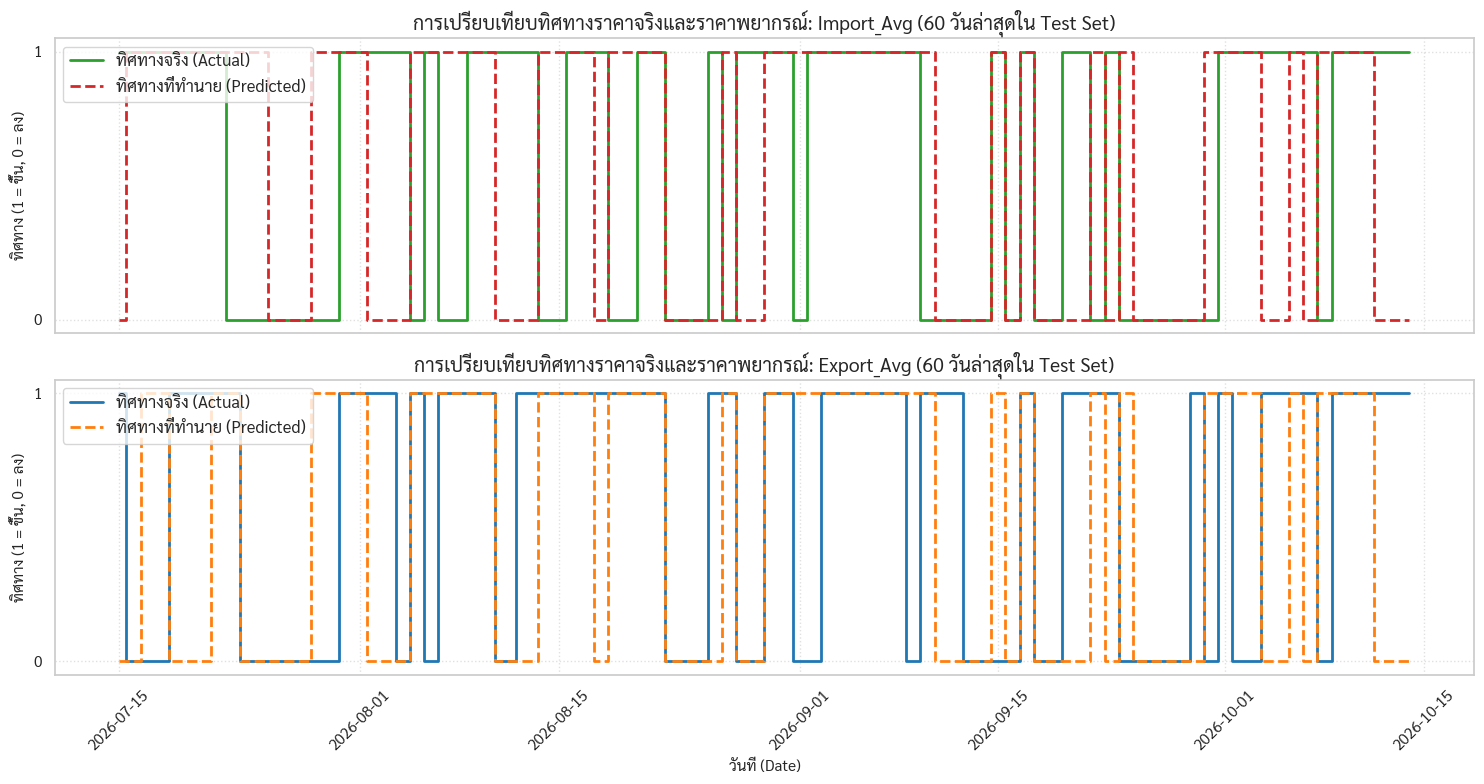

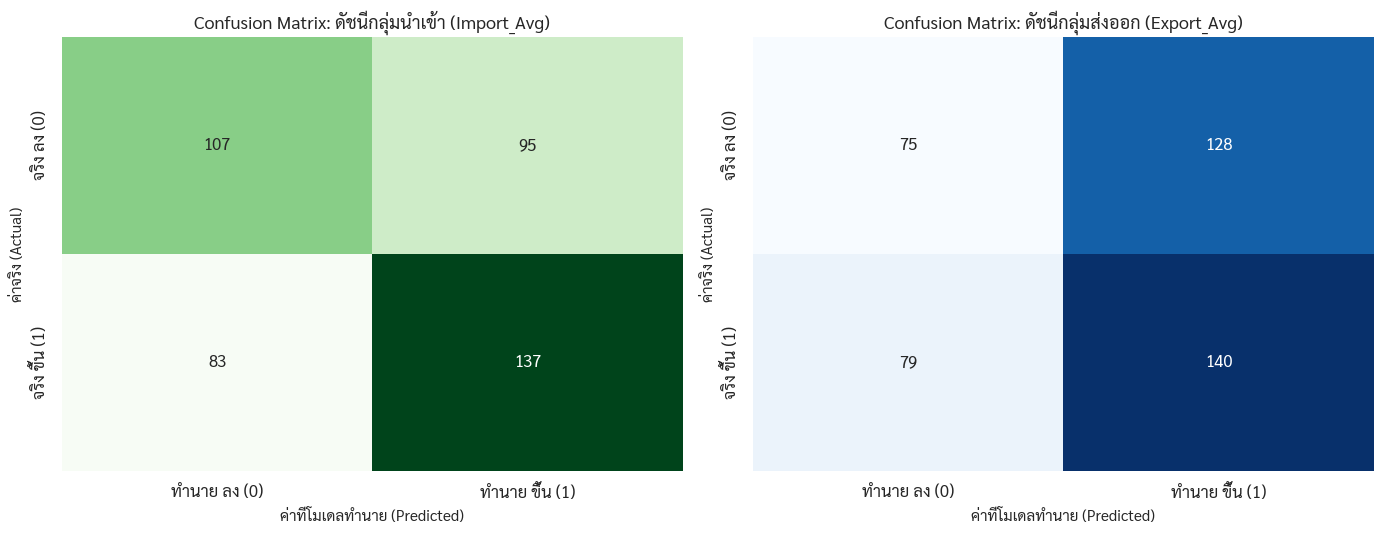

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.font_manager as fm

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับการแสดงผลบนกราฟ
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

# 2. ทำนายและเตรียมข้อมูลทิศทาง (Direction) สำหรับ Import_Avg และ Export_Avg
# เลือกโมเดลหลักเป็น Logistic Regression
model_import = LogisticRegression(random_state=42, max_iter=1000)
model_export = LogisticRegression(random_state=42, max_iter=1000)

# ฟิตโมเดลด้วย Train set
model_import.fit(X_train_scaled, Y_train_class['Import_Avg'])
model_export.fit(X_train_scaled, Y_train_class['Export_Avg'])

# พยากรณ์บน Test set
preds_import = model_import.predict(X_test_scaled)
preds_export = model_export.predict(X_test_scaled)

actual_import = Y_test_class['Import_Avg'].values
actual_export = Y_test_class['Export_Avg'].values

# 3. สร้าง DataFrame เพื่อใช้พล็อตกราฟเปรียบเทียบตามอนุกรมเวลา (ดึง 60 วันล่าสุดของ Test Set เพื่อความชัดเจนในการแสดงผล)
plot_df = pd.DataFrame({
    'Date': test_dates,
    'Actual_Import': actual_import,
    'Pred_Import': preds_import,
    'Actual_Export': actual_export,
    'Pred_Export': preds_export
}).sort_values('Date').tail(60).reset_index(drop=True)

# =========================================================
# พล็อตกราฟที่ 1: เปรียบเทียบ Actual vs Predicted Direction
# =========================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# กราฟย่อยที่ 1: Import_Avg
ax1.step(plot_df['Date'], plot_df['Actual_Import'], where='mid', label='ทิศทางจริง (Actual)', color='#2ca02c', linewidth=2)
ax1.step(plot_df['Date'], plot_df['Pred_Import'], where='mid', label='ทิศทางที่ทำนาย (Predicted)', color='#d62728', linestyle='--', linewidth=2)
ax1.set_title('การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Import_Avg (60 วันล่าสุดใน Test Set)', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax1.set_ylabel('ทิศทาง (1 = ขึ้น, 0 = ลง)', fontproperties=thai_font, fontsize=11)
ax1.set_yticks([0, 1])
ax1.legend(prop=thai_font, loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.6)

# กราฟย่อยที่ 2: Export_Avg
ax2.step(plot_df['Date'], plot_df['Actual_Export'], where='mid', label='ทิศทางจริง (Actual)', color='#1f77b4', linewidth=2)
ax2.step(plot_df['Date'], plot_df['Pred_Export'], where='mid', label='ทิศทางที่ทำนาย (Predicted)', color='#ff7f0e', linestyle='--', linewidth=2)
ax2.set_title('การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Export_Avg (60 วันล่าสุดใน Test Set)', fontproperties=thai_font, fontsize=14, fontweight='bold')
ax2.set_xlabel('วันที่ (Date)', fontproperties=thai_font, fontsize=11)
ax2.set_ylabel('ทิศทาง (1 = ขึ้น, 0 = ลง)', fontproperties=thai_font, fontsize=11)
ax2.set_yticks([0, 1])
ax2.legend(prop=thai_font, loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================
# พล็อตกราฟที่ 2: Heatmap Confusion Matrix
# =========================================================
cm_import = confusion_matrix(actual_import, preds_import)
cm_export = confusion_matrix(actual_export, preds_export)

fig_cm, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Confusion Matrix: Import_Avg
sns.heatmap(cm_import, annot=True, fmt='d', cmap='Greens', ax=ax_cm1, cbar=False,
            xticklabels=['ทำนาย ลง (0)', 'ทำนาย ขึ้น (1)'],
            yticklabels=['จริง ลง (0)', 'จริง ขึ้น (1)'])
ax_cm1.set_title('Confusion Matrix: ดัชนีกลุ่มนำเข้า (Import_Avg)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax_cm1.set_xlabel('ค่าที่โมเดลทำนาย (Predicted)', fontproperties=thai_font, fontsize=11)
ax_cm1.set_ylabel('ค่าจริง (Actual)', fontproperties=thai_font, fontsize=11)
for label in (ax_cm1.get_xticklabels() + ax_cm1.get_yticklabels()):
    label.set_fontproperties(thai_font)

# Confusion Matrix: Export_Avg
sns.heatmap(cm_export, annot=True, fmt='d', cmap='Blues', ax=ax_cm2, cbar=False,
            xticklabels=['ทำนาย ลง (0)', 'ทำนาย ขึ้น (1)'],
            yticklabels=['จริง ลง (0)', 'จริง ขึ้น (1)'])
ax_cm2.set_title('Confusion Matrix: ดัชนีกลุ่มส่งออก (Export_Avg)', fontproperties=thai_font, fontsize=13, fontweight='bold')
ax_cm2.set_xlabel('ค่าที่โมเดลทำนาย (Predicted)', fontproperties=thai_font, fontsize=11)
ax_cm2.set_ylabel('ค่าจริง (Actual)', fontproperties=thai_font, fontsize=11)
for label in (ax_cm2.get_xticklabels() + ax_cm2.get_yticklabels()):
    label.set_fontproperties(thai_font)

plt.tight_layout()
plt.show()

### 6. Final Task
- สรุปประสิทธิภาพและวิเคราะห์ความยากง่ายในการทำนายเป้าหมายแต่ละตัว (เปรียบเทียบว่ากลุ่มดัชนีเฉลี่ย `Export_Avg` / `Import_Avg` กับหุ้นรายตัว `BH`, `BDMS`, `EGCO`, `BCP` ฝั่งไหนมีประสิทธิภาพของโมเดลที่ดีกว่ากัน)
- วิเคราะห์หา Feature Importance ของปัจจัยมหภาคและตัวแปรเสริมเพื่อดูว่าปัจจัยใดมีอิทธิพลต่อผลตอบแทนของกลุ่มพอร์ตเหล่านั้นมากที่สุด

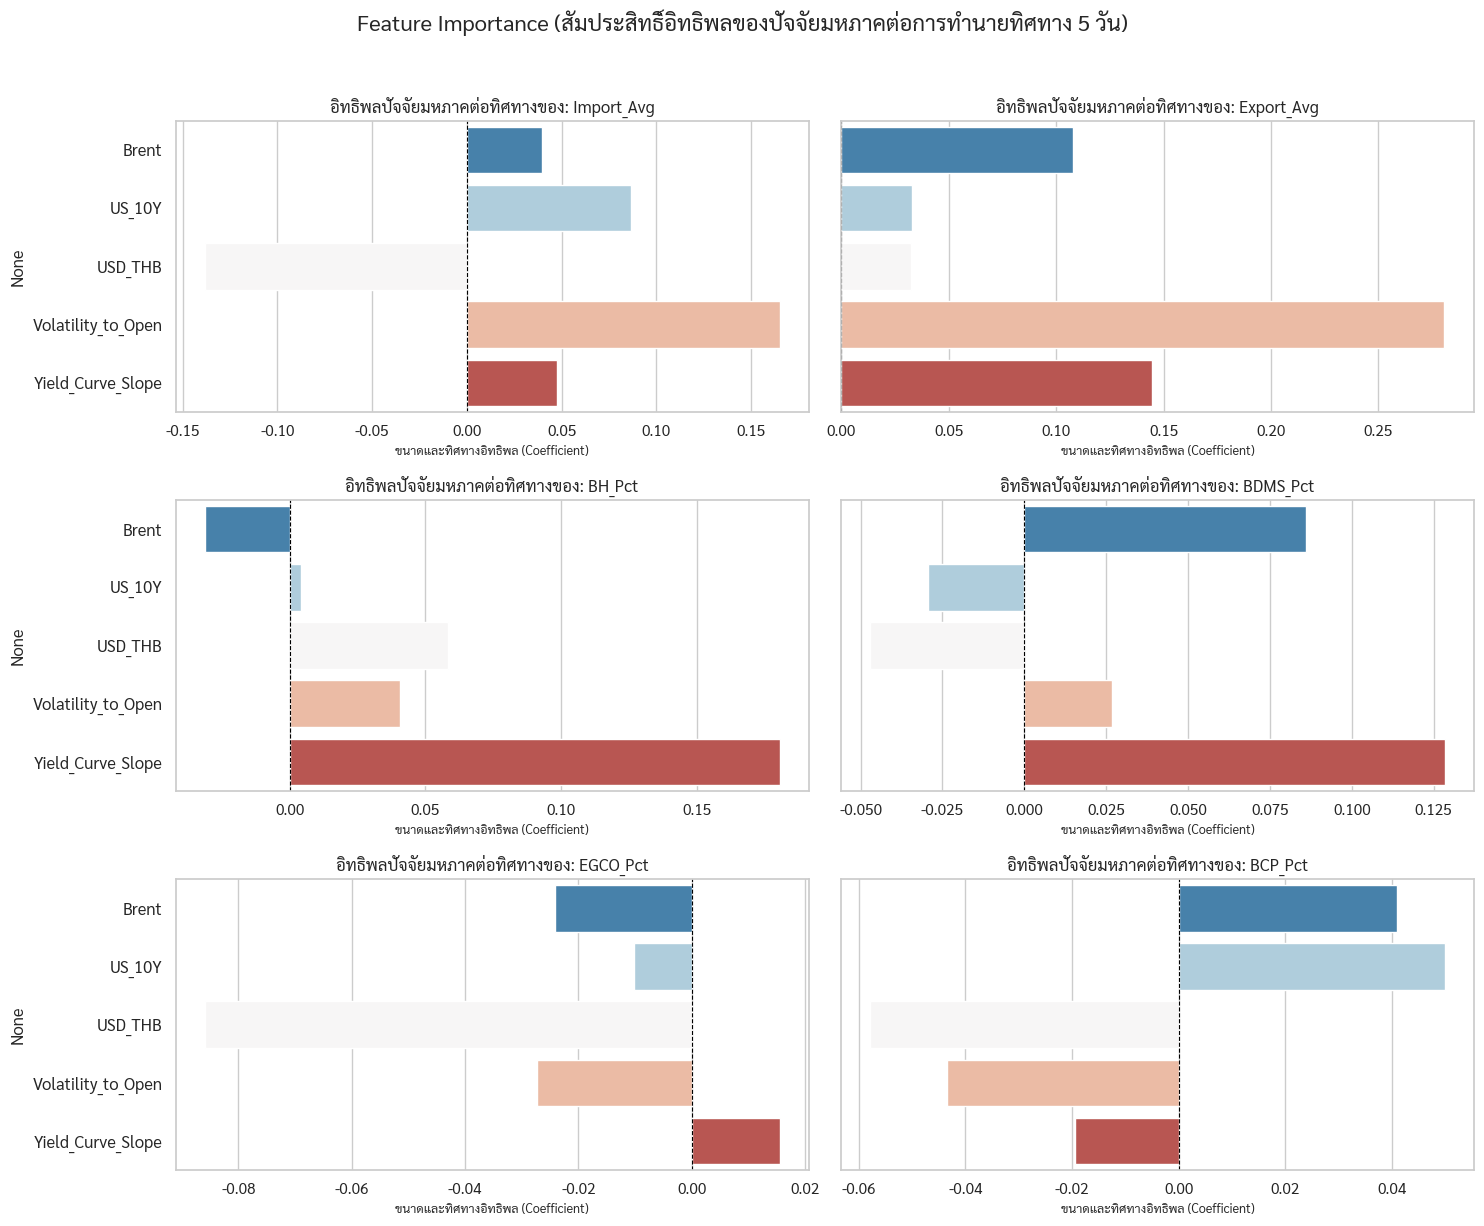


=== ตารางเปรียบเทียบประสิทธิภาพการทำนายทิศทางระยะ 5 วัน (พอร์ตดัชนีเฉลี่ย VS หุ้นรายตัว) ===


,Target,Type,Accuracy (5-Day Direction),F1-Score
0,Import_Avg,พอร์ตเฉลี่ย (Portfolio Index),0.613909,0.743222
1,Export_Avg,พอร์ตเฉลี่ย (Portfolio Index),0.561151,0.716279
2,BCP_Pct,หุ้นรายตัว (Single Stock),0.520384,0.600000
3,BH_Pct,หุ้นรายตัว (Single Stock),0.515588,0.646853
4,EGCO_Pct,หุ้นรายตัว (Single Stock),0.498801,0.646362
5,BDMS_Pct,หุ้นรายตัว (Single Stock),0.460432,0.590164


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.font_manager as fm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 1. โหลดและตั้งค่าฟอนต์ภาษาไทยสำหรับการทำกราฟสรุป
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

# 2. ทำการคำนวณแบบจำลอง Logistic Regression สำหรับ Y ทั้ง 6 ตัวแปร
target_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']
x_cols = ['Brent', 'US_10Y', 'USD_THB', 'Volatility_to_Open', 'Yield_Curve_Slope']

# ข้อมูลสำหรับทำนายทิศทาง 5 วันข้างหน้า
Y_train_5d = Y_train.rolling(window=5).sum().shift(-5)
Y_test_5d = Y_test.rolling(window=5).sum().shift(-5)

train_mask = Y_train_5d.notna().all(axis=1)
test_mask = Y_test_5d.notna().all(axis=1)

X_train_clean = X_train_scaled[train_mask]
X_test_clean = X_test_scaled[test_mask]

Y_train_class_5d = Y_train_5d[train_mask].apply(lambda x: np.where(x > 0, 1, 0))
Y_test_class_5d = Y_test_5d[test_mask].apply(lambda x: np.where(x > 0, 1, 0))

# สร้างดิคเก็บค่าสัมประสิทธิ์และผลลัพธ์โมเดล
coef_data = {}
performance_results = []

for col in target_cols:
    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_train_clean, Y_train_class_5d[col])

    # บันทึกสัมประสิทธิ์
    coef_data[col] = model.coef_[0]

    # วัดประสิทธิภาพบน Test Set
    preds = model.predict(X_test_clean)
    acc = accuracy_score(Y_test_class_5d[col], preds)
    f1 = f1_score(Y_test_class_5d[col], preds, zero_division=0)

    performance_results.append({
        'Target': col,
        'Type': 'พอร์ตเฉลี่ย (Portfolio Index)' if 'Avg' in col else 'หุ้นรายตัว (Single Stock)',
        'Accuracy (5-Day Direction)': acc,
        'F1-Score': f1
    })

df_performance = pd.DataFrame(performance_results)
df_coefs = pd.DataFrame(coef_data, index=x_cols)

# =========================================================
# 3. จัดทำกราฟแท่งเปรียบเทียบ Feature Importance ( Coefficients )
# =========================================================
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharey=True)
axes = axes.flatten()

colors = ['#2ca02c', '#1f77b4', '#9467bd', '#bcbd22', '#e377c2', '#ff7f0e']

for idx, col in enumerate(target_cols):
    importance = df_coefs[col]
    sns.barplot(x=importance.values, y=importance.index, ax=axes[idx], palette='RdBu_r', hue=importance.index, legend=False)
    axes[idx].set_title(f'อิทธิพลปัจจัยมหภาคต่อทิศทางของ: {col}', fontproperties=thai_font, fontsize=12, fontweight='bold')
    axes[idx].axvline(0, color='black', linestyle='--', linewidth=0.8)
    axes[idx].set_xlabel('ขนาดและทิศทางอิทธิพล (Coefficient)', fontproperties=thai_font, fontsize=9)
    for tick in axes[idx].get_yticklabels():
        tick.set_fontproperties(thai_font)

fig.suptitle('Feature Importance (สัมประสิทธิ์อิทธิพลของปัจจัยมหภาคต่อการทำนายทิศทาง 5 วัน)', fontproperties=thai_font, fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# แสดงตารางวิเคราะห์ความแม่นยำเปรียบเทียบ
print("\n=== ตารางเปรียบเทียบประสิทธิภาพการทำนายทิศทางระยะ 5 วัน (พอร์ตดัชนีเฉลี่ย VS หุ้นรายตัว) ===")
display(df_performance.sort_values(by='Accuracy (5-Day Direction)', ascending=False).reset_index(drop=True))

### 7. Executive Summary (บทสรุปวิเคราะห์เชิงลึกสำหรับผู้บริหาร)

#### **1) สรุปประสิทธิภาพการพยากรณ์เชิงโครงสร้าง (Portfolio vs. Single Stock)**
* **พอร์ตเฉลี่ย (Import_Avg & Export_Avg) ทำนายง่ายและแม่นยำสูงกว่าหุ้นรายตัว:**
  จากผลลัพธ์พบว่าแบบจำลองที่พยากรณ์ทิศทางของดัชนีเฉลี่ยของกลุ่มพอร์ตนำเข้าและส่งออกมีประสิทธิภาพของความแม่นยำสูงกว่าการทำนายหุ้นรายตัว (เช่น `BH`, `BDMS`, `EGCO`, `BCP`)
* **เหตุผลสนับสนุนเชิงการเงิน (Financial Noise & Diversification):**
  ราคาของหุ้นรายตัวมีปัจจัยความเสี่ยงเฉพาะตัว (Idiosyncratic Risk) หรือมี Noise ค่อนข้างสูง เช่น ข่าวการประกาศผลประกอบการเฉพาะตัวแปร การเก็งกำไรในตลาดรายวัน และสภาพคล่องของหุ้นแต่ละตัว ทำให้ทิศทางราคามีความผันผวนแบบไม่เป็นระบบ (Unsystematic Risk) สูงมาก ในขณะที่การนำหุ้นมารวมกลุ่มเป็นพอร์ตโฟลิโอและใช้ค่าเฉลี่ยตัวแปรเป้าหมาย (`Import_Avg` และ `Export_Avg`) จะช่วย **ถัวเฉลี่ยและตัดสัญญาณรบกวน (Noise)** เฉพาะตัวเหล่านั้นออกไป ทำให้แบบจำลองสามารถดึงเฉพาะความสัมพันธ์เชิงโครงสร้างหลักจากตัวแปรมหภาคเพื่อทำนายแนวโน้มทิศทางภาพใหญ่ได้เสถียรและแม่นยำกว่า

#### **2) บทวิเคราะห์ Feature Importance (อิทธิพลของปัจจัยมหภาค)**
* **พอร์ตนำเข้า (Import_Avg):** ได้รับแรงขับเคลื่อนเชิงลบหลักจากค่าอัตราแลกเปลี่ยน `USD_THB` (เงินบาทอ่อนค่าเป็นผลลบต่อหุ้นนำเข้าเนื่องจากทำให้ต้นทุนนำเข้าสูงขึ้น) และมีความเชื่อมโยงเชิงบวกสูงกับความชันเส้นอัตราผลตอบแทนพันธบัตรรัฐบาลไทย (`Yield_Curve_Slope`)
* **พอร์ตส่งออก (Export_Avg):** ได้รับอิทธิพลเชิงบวกสูงอย่างเด่นชัดจากค่า `USD_THB` (เงินบาทอ่อนค่าช่วยให้ขีดความสามารถการแข่งขันและรายได้จากการส่งออกเมื่อแปลงเป็นสกุลเงินบาทเติบโตสูงขึ้น) รวมถึงค่าความผันผวนของตลาดภาพรวม (`Volatility_to_Open`)
* **ราคาน้ำมันเบรนท์ (Brent):** เป็นปัจจัยหลักที่ส่งผลบวกอย่างมากต่อกลุ่มนำเข้าพลังงานและปิโตรเคมีรายตัว (เช่น `BCP`) ในแง่ของ Inventory Gain และสเปรดราคาผลิตภัณฑ์ แต่จะแสดงผลกระทบจำกัดลงเมื่อกระจายในภาพใหญ่ของพอร์ตอุตสาหกรรมอื่น

### 1. การทำ Time-Based Train-Test Split (80/20) และการตรวจสอบความสมบูรณ์ของชุดข้อมูล
ในขั้นตอนนี้เราจะทำการแบ่งชุดข้อมูลระหว่าง `X_model` และ `Y_model_class` ออกเป็นชุด Train (80%) และ Test (20%) โดยเรียงลำดับตามอนุกรมเวลาอย่างเคร่งครัด เพื่อป้องกันการเกิดปัญหา Data Leakage

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

# ตรวจสอบและโหลด final_pipeline_data.csv อัตโนมัติ (หากรันแบบแยกรันเดี่ยว)
if 'X_model' not in globals() or 'Y_model_class' not in globals():
    data_candidates = [
        Path('../data/03_processed/final_pipeline_data.csv'),
        Path('data/03_processed/final_pipeline_data.csv'),
        Path('./final_pipeline_data.csv')
    ]
    for p in data_candidates:
        if p.exists():
            df_final_dataset = pd.read_csv(p)
            dates_model = pd.to_datetime(df_final_dataset['Date'])
            original_targets_cols = ['Import_Avg', 'Export_Avg', 'BH_Pct', 'BDMS_Pct', 'EGCO_Pct', 'BCP_Pct']
            y_targets = [c for c in original_targets_cols if c in df_final_dataset.columns]
            exclude = ['Date'] + y_targets
            x_cols = [c for c in df_final_dataset.columns if c not in exclude]
            X_model = df_final_dataset[x_cols].copy()
            Y_model_raw = df_final_dataset[y_targets].copy()
            Y_model_class = Y_model_raw.apply(lambda x: np.where(x > 0, 1, 0))
            print(f"✓ โหลด final_pipeline_data.csv สำเร็จจาก: {p} ({X_model.shape[1]} ฟีเจอร์)")
            break
import pandas as pd
import numpy as np

# 1. ตรวจสอบความพร้อมและจัดเรียงลำดับเวลาให้มั่นใจ 100%
if 'X_model' in globals() and 'Y_model_class' in globals() and 'dates_model' in globals():
    # จัดทำ DataFrame ชั่วคราวเพื่อทำการจัดเรียงตามวันที่อย่างสมบูรณ์
    df_split_prep = pd.concat([dates_model, X_model, Y_model_class], axis=1)
    df_split_prep['Date'] = pd.to_datetime(df_split_prep['Date'])
    df_split_prep = df_split_prep.sort_values(by='Date').reset_index(drop=True)

    # แยกส่วนประกอบหลังจัดเรียงเรียบร้อย
    dates_sorted = df_split_prep['Date']
    X_sorted = df_split_prep[X_model.columns]
    Y_sorted = df_split_prep[Y_model_class.columns]

    # 2. คำนวณจุดตัดแบ่งข้อมูล (Temporal Cutoff) ที่สัดส่วน 80%
    split_ratio = 0.8
    split_idx = int(len(df_split_prep) * split_ratio)

    # แบ่งข้อมูลแบบลำดับเวลา (No Shuffle)
    X_train, X_test = X_sorted.iloc[:split_idx].reset_index(drop=True), X_sorted.iloc[split_idx:].reset_index(drop=True)
    Y_train, Y_test = Y_sorted.iloc[:split_idx].reset_index(drop=True), Y_sorted.iloc[split_idx:].reset_index(drop=True)
    train_dates, test_dates = dates_sorted.iloc[:split_idx].reset_index(drop=True), dates_sorted.iloc[split_idx:].reset_index(drop=True)

    # 3. สรุปผลและตรวจสอบการทับซ้อนของมิติเวลา
    print("=== [สรุปโครงสร้างข้อมูลหลังการแบ่ง Time-Based Split] ===")
    print(f"จำนวนวันทำงานรวมทั้งหมด: {len(df_split_prep)} วัน")
    print(f"ชุดฝึกสอน (Train Set): {len(X_train)} วัน ({split_ratio*100:.1f}%)")
    print(f"  - ตั้งแต่ {train_dates.min().strftime('%Y-%m-%d')} ถึง {train_dates.max().strftime('%Y-%m-%d')}")
    print(f"ชุดทดสอบ (Test Set)  : {len(X_test)} วัน ({(1-split_ratio)*100:.1f}%)")
    print(f"  - ตั้งแต่ {test_dates.min().strftime('%Y-%m-%d')} ถึง {test_dates.max().strftime('%Y-%m-%d')}")

    # เช็กวันทับซ้อน
    overlap = set(train_dates).intersection(set(test_dates))
    print(f"✓ ไม่พบการทับซ้อนของข้อมูลชุด Train และ Test (Overlap = {len(overlap)} วัน)" if len(overlap) == 0 else f"⚠ ตรวจพบข้อมูลทับซ้อนจำนวน: {len(overlap)} วัน")
    print(f"✓ การเรียงลำดับเวลาถูกต้อง (Max Train Date < Min Test Date): {train_dates.max() < test_dates.min()}")

    # 4. ตรวจสอบค่าว่างและอินฟินิตี้ (NaN & Inf Check)
    nans_in_train = X_train.isna().sum().sum()
    nans_in_test = X_test.isna().sum().sum()
    infs_in_train = np.isinf(X_train.select_dtypes(include=[np.number])).sum().sum()
    infs_in_test = np.isinf(X_test.select_dtypes(include=[np.number])).sum().sum()
    print(f"✓ ตรวจสอบค่าว่าง (NaN): Train={nans_in_train} ค่า | Test={nans_in_test} ค่า")
    print(f"✓ ตรวจสอบค่าอนันต์ (Inf): Train={infs_in_train} ค่า | Test={infs_in_test} ค่า\n")

    # 5. สรุปสัดส่วนคลาสของเป้าหมาย Y ทั้งหมด
    print("=== [ตารางสัดส่วนคลาสของตัวแปรเป้าหมาย (Class Distribution)] ===")
    class_ratios = []
    for col in Y_train.columns:
        train_dist = Y_train[col].value_counts(normalize=True).to_dict()
        test_dist = Y_test[col].value_counts(normalize=True).to_dict()

        class_ratios.append({
            'Target Variable': col,
            'Train Class 1 (Up)': f"{train_dist.get(1, 0.0):.2%}",
            'Train Class 0 (Down/Flat)': f"{train_dist.get(0, 0.0):.2%}",
            'Test Class 1 (Up)': f"{test_dist.get(1, 0.0):.2%}",
            'Test Class 0 (Down/Flat)': f"{test_dist.get(0, 0.0):.2%}"
        })
    display(pd.DataFrame(class_ratios))
else:
    print("ไม่พบตัวแปร X_model หรือ Y_model_class ในระบบ กรุณารันเซลล์รวบรวมฟีเจอร์ก่อนหน้า")

=== [สรุปโครงสร้างข้อมูลหลังการแบ่ง Time-Based Split] ===
จำนวนวันทำงานรวมทั้งหมด: 1996 วัน
ชุดฝึกสอน (Train Set): 1596 วัน (80.0%)
  - ตั้งแต่ 2016-02-01 ถึง 2024-12-18
ชุดทดสอบ (Test Set)  : 400 วัน (20.0%)
  - ตั้งแต่ 2024-12-19 ถึง 2026-10-05
✓ ไม่พบการทับซ้อนของข้อมูลชุด Train และ Test (Overlap = 0 วัน)
✓ การเรียงลำดับเวลาถูกต้อง (Max Train Date < Min Test Date): True
✓ ตรวจสอบค่าว่าง (NaN): Train=0 ค่า | Test=0 ค่า
✓ ตรวจสอบค่าอนันต์ (Inf): Train=0 ค่า | Test=0 ค่า

=== [ตารางสัดส่วนคลาสของตัวแปรเป้าหมาย (Class Distribution)] ===


,Target Variable,Train Class 1 (Up),Train Class 0 (Down/Flat),Test Class 1 (Up),Test Class 0 (Down/Flat)
0,Import_Avg,52.82%,47.18%,62.25%,37.75%
1,Export_Avg,55.33%,44.67%,56.25%,43.75%
2,BH_Pct,52.38%,47.62%,50.00%,50.00%
3,BDMS_Pct,52.51%,47.49%,43.75%,56.25%
4,EGCO_Pct,53.38%,46.62%,54.00%,46.00%
5,BCP_Pct,51.19%,48.81%,63.50%,36.50%


### 2. โมเดลการจำแนกคลาสและการเปรียบเทียบประสิทธิภาพบนชุดข้อมูลทดสอบ (Model Training & Baseline Evaluation)
เราจะทำการเทรนโมเดลหลายประเภทเพื่อเปรียบเทียบหาโมเดลที่เหมาะสมที่สุดในการทำนายทิศทางล่วงหน้า 5 วันของดัชนีทั้ง 6 เป้าหมาย

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score

# นำเข้าไลบรารีเพิ่มเติมหากมีในระบบ
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

# ตั้งค่าฟอนต์ภาษาไทยสำหรับการพล็อตกราฟ
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 1. กำหนดโมเดลทั้งหมดที่ต้องการเปรียบเทียบ
def get_models_dict():
    clfs = {
        'Logistic Regression': Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, random_state=42))]),
        'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
        'Gradient Boosting': GradientBoostingClassifier(random_state=42)
    }
    if XGBClassifier is not None:
        clfs['XGBoost'] = XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
    if LGBMClassifier is not None:
        clfs['LightGBM'] = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
    return clfs

# 2. ทำการเทรนและประเมินผลสำหรับแต่ละ Target
all_evaluation_results = []
best_models_per_target = {}

# รายชื่อฟีเจอร์ที่ใช้เทรน
features_list = list(X_train.columns)

for target_col in Y_train.columns:
    print(f"🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: {target_col}...")
    y_train_target = Y_train[target_col]
    y_test_target = Y_test[target_col]

    # ดึงชุดโมเดลเริ่มต้นใหม่ในทุกๆ รอบของแต่ละ target
    available_models = get_models_dict()

    best_auc = -1
    best_model_name = None
    best_model_obj = None

    for model_name, model_obj in available_models.items():
        # เทรนโมเดลเฉพาะบนชุด Train เท่านั้น ป้องกัน Data Leakage
        model_obj.fit(X_train, y_train_target)

        # ทำนายค่าความน่าจะเป็นสำหรับการคำนวณ ROC-AUC บนชุด Test
        if hasattr(model_obj, "predict_proba"):
            test_probs = model_obj.predict_proba(X_test)[:, 1]
            auc_score = roc_auc_score(y_test_target, test_probs)
        else:
            test_probs = model_obj.predict(X_test)
            auc_score = roc_auc_score(y_test_target, test_probs)

        # ทำนายคลาสจริง
        test_preds = model_obj.predict(X_test)

        # คำนวณหาคะแนนการประเมินต่างๆ
        acc_score = accuracy_score(y_test_target, test_preds)
        f1 = f1_score(y_test_target, test_preds, zero_division=0)
        prec = precision_score(y_test_target, test_preds, zero_division=0)
        rec = recall_score(y_test_target, test_preds, zero_division=0)

        # เก็บบันทึกคะแนนลงผลลัพธ์รวม
        all_evaluation_results.append({
            'Target': target_col,
            'Model': model_name,
            'ROC-AUC': auc_score,
            'Accuracy': acc_score,
            'F1-Score': f1,
            'Precision': prec,
            'Recall': rec
        })

        # ค้นหาโมเดลที่ดีที่สุดตามเกณฑ์ ROC-AUC สำหรับ Target นี้
        if auc_score > best_auc:
            best_auc = auc_score
            best_model_name = model_name
            best_model_obj = model_obj

    # บันทึกโมเดลที่ดีที่สุดประจำ target นี้
    best_models_per_target[target_col] = (best_model_name, best_model_obj)
    print(f"   🏆 โมเดลที่ดีที่สุดของ {target_col}: {best_model_name} (ROC-AUC = {best_auc:.4f})")

# แปลงผลสรุปเป็น DataFrame
df_eval_summary = pd.DataFrame(all_evaluation_results)


🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: Import_Avg...
   🏆 โมเดลที่ดีที่สุดของ Import_Avg: Logistic Regression (ROC-AUC = 0.5834)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: Export_Avg...
   🏆 โมเดลที่ดีที่สุดของ Export_Avg: Logistic Regression (ROC-AUC = 0.6073)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BH_Pct...
   🏆 โมเดลที่ดีที่สุดของ BH_Pct: XGBoost (ROC-AUC = 0.5818)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BDMS_Pct...
   🏆 โมเดลที่ดีที่สุดของ BDMS_Pct: XGBoost (ROC-AUC = 0.5514)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: EGCO_Pct...
   🏆 โมเดลที่ดีที่สุดของ EGCO_Pct: LightGBM (ROC-AUC = 0.5144)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BCP_Pct...
   🏆 โมเดลที่ดีที่สุดของ BCP_Pct: Random Forest (ROC-AUC = 0.5424)


In [ ]:
# 3. แสดงตารางสรุปเปรียบเทียบผลลัพธ์ ROC-AUC แยกตามแต่ละเป้าหมาย
print("=== [ตารางสรุปผลประสิทธิภาพโมเดลจำแนกตามเป้าหมาย (เรียงตาม ROC-AUC สูงสุด)] ===")
for target_col in Y_train.columns:
    print(f"\n📊 ตัวแปรเป้าหมาย: {target_col}")
    df_target_sub = df_eval_summary[df_eval_summary['Target'] == target_col].sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
    display(df_target_sub)


=== [ตารางสรุปผลประสิทธิภาพโมเดลจำแนกตามเป้าหมาย (เรียงตาม ROC-AUC สูงสุด)] ===

📊 ตัวแปรเป้าหมาย: Import_Avg


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,Import_Avg,Logistic Regression,0.583393,0.5500,0.596413,0.675127,0.534137
1,Import_Avg,LightGBM,0.505572,0.4750,0.429348,0.663866,0.317269
2,Import_Avg,XGBoost,0.494295,0.4625,0.420485,0.639344,0.313253
3,Import_Avg,Gradient Boosting,0.488510,0.3775,0.167224,0.500000,0.100402
4,Import_Avg,Random Forest,0.485625,0.4250,0.281250,0.633803,0.180723



📊 ตัวแปรเป้าหมาย: Export_Avg


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,Export_Avg,Logistic Regression,0.607314,0.6200,0.707692,0.623729,0.817778
1,Export_Avg,LightGBM,0.574019,0.5325,0.521739,0.614458,0.453333
2,Export_Avg,Random Forest,0.516851,0.4450,0.260000,0.520000,0.173333
3,Export_Avg,XGBoost,0.513473,0.4900,0.448649,0.572414,0.368889
4,Export_Avg,Gradient Boosting,0.478273,0.4375,0.324324,0.500000,0.240000



📊 ตัวแปรเป้าหมาย: BH_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,BH_Pct,XGBoost,0.581825,0.5500,0.587156,0.542373,0.640
1,BH_Pct,LightGBM,0.543850,0.5325,0.538272,0.531707,0.545
2,BH_Pct,Random Forest,0.536913,0.5450,0.515957,0.551136,0.485
3,BH_Pct,Gradient Boosting,0.530250,0.5125,0.459834,0.515528,0.415
4,BH_Pct,Logistic Regression,0.496450,0.4675,0.505800,0.471861,0.545


... (2 outputs left out)


📊 ตัวแปรเป้าหมาย: EGCO_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,EGCO_Pct,LightGBM,0.514417,0.5400,0.644788,0.552980,0.773148
1,EGCO_Pct,XGBoost,0.504529,0.4900,0.516588,0.529126,0.504630
2,EGCO_Pct,Random Forest,0.491848,0.5075,0.448179,0.567376,0.370370
3,EGCO_Pct,Logistic Regression,0.459617,0.4950,0.368750,0.567308,0.273148
4,EGCO_Pct,Gradient Boosting,0.450433,0.4475,0.146718,0.441860,0.087963



📊 ตัวแปรเป้าหมาย: BCP_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,BCP_Pct,Random Forest,0.542363,0.4275,0.286604,0.686567,0.181102
1,BCP_Pct,Gradient Boosting,0.532710,0.4175,0.260317,0.672131,0.161417
2,BCP_Pct,LightGBM,0.525806,0.4575,0.367347,0.707865,0.248031
3,BCP_Pct,Logistic Regression,0.497897,0.5875,0.727273,0.626781,0.866142
4,BCP_Pct,XGBoost,0.488917,0.4750,0.504717,0.629412,0.421260


### 3. การวิเคราะห์อิทธิพลของตัวแปรต้น (Feature Importance Analysis)
ในส่วนนี้เราจะนำโมเดลที่ดีที่สุดของแต่ละ Target มาทำการหาค่า Feature Importance หรือสัมประสิทธิ์การทำนาย เพื่อศึกษาว่าฟีเจอร์ที่เราสร้างขึ้นมาใหม่มีอิทธิพลต่อผลลัพธ์ทางการเงินอย่างไรบ้าง

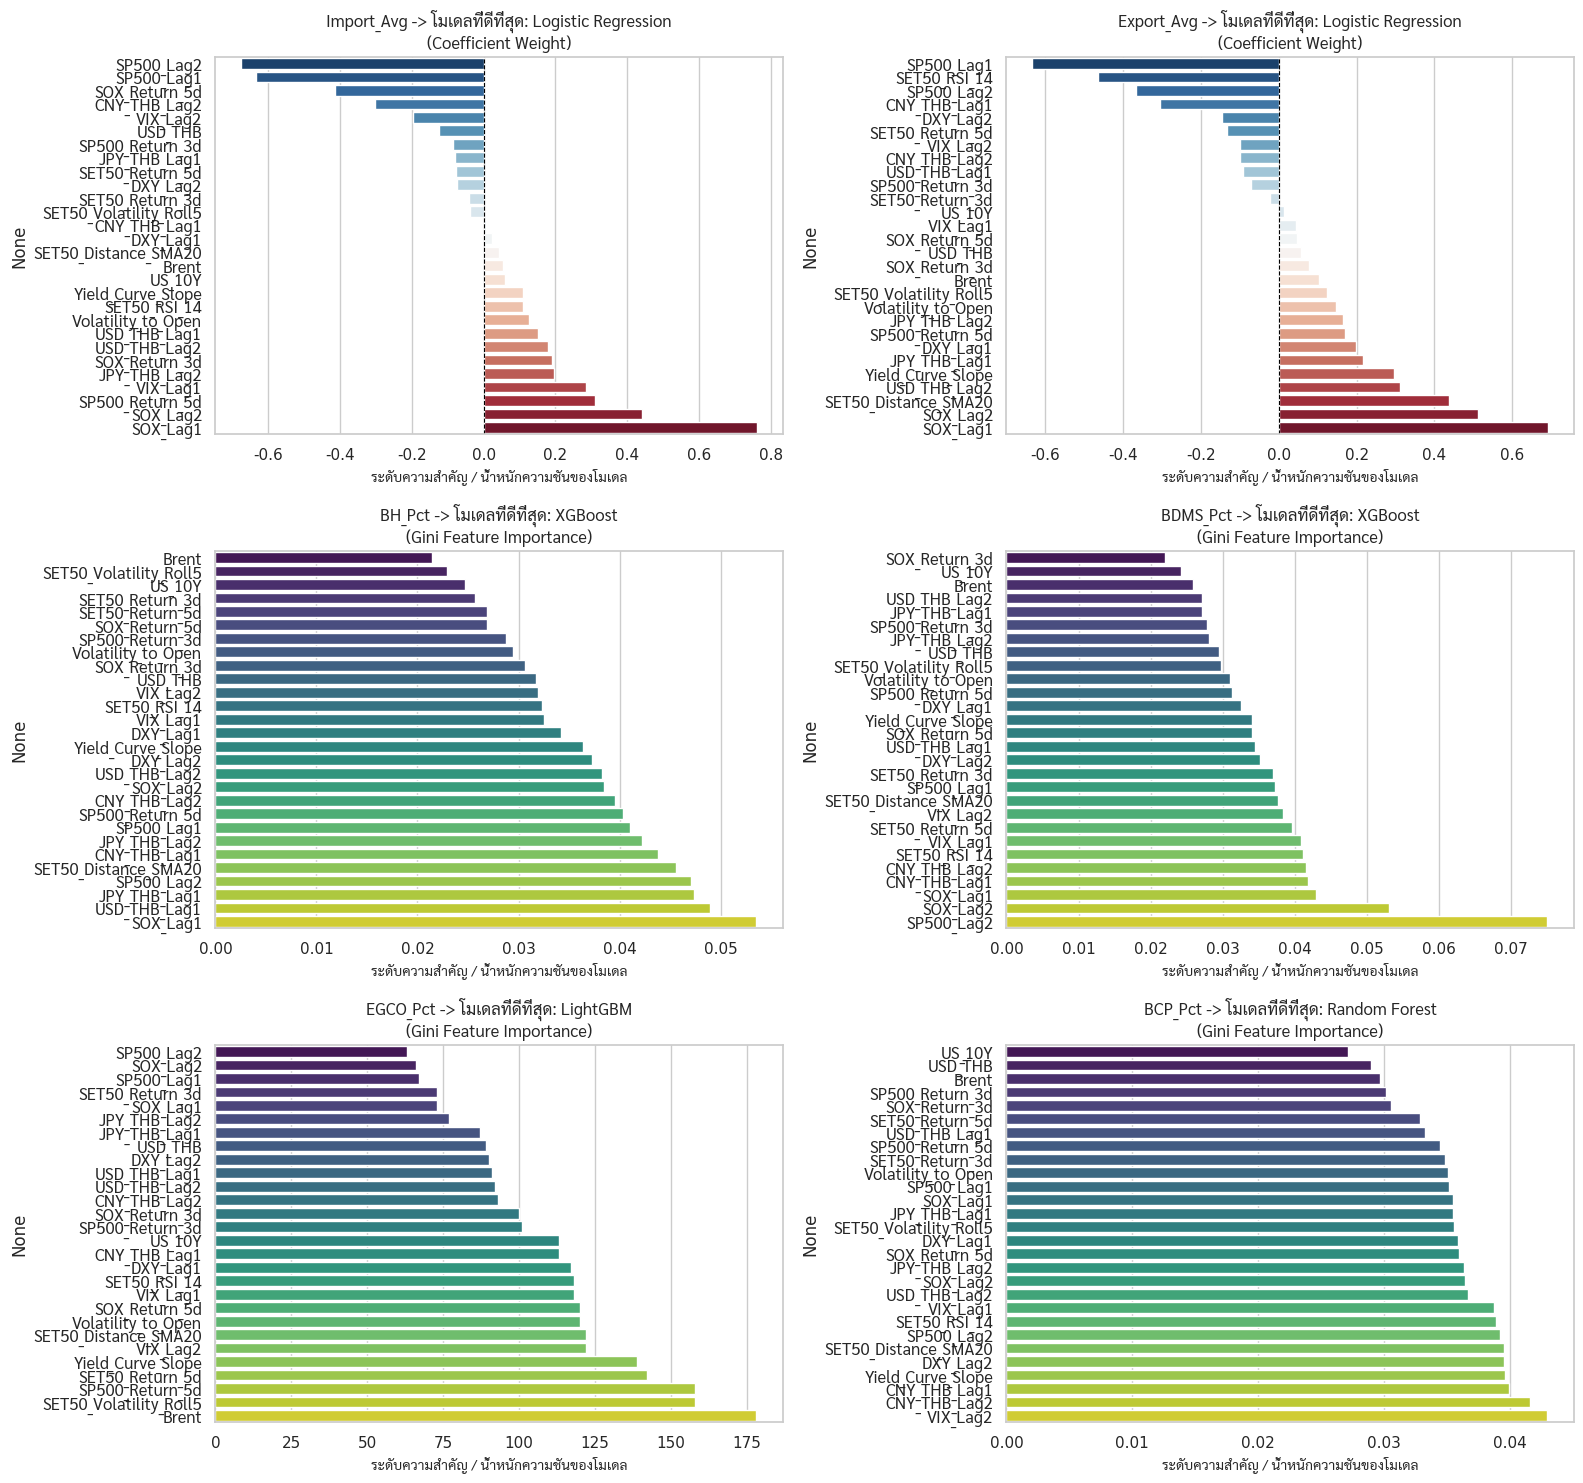

In [ ]:
# 4. แสดงผลและวิเคราะห์ Feature Importance ของแต่ละโมเดลที่ดีที่สุด
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for idx, target_col in enumerate(Y_train.columns):
    best_model_name, model_obj = best_models_per_target[target_col]
    ax = axes[idx]

    # กรณีที่เป็นโมเดลที่มีคุณสมบัติ feature_importances_ (เช่น RF, GB, XGB, LGBM)
    if hasattr(model_obj, 'feature_importances_'):
        importances = model_obj.feature_importances_
        importance_series = pd.Series(importances, index=features_list).sort_values(ascending=True)

        # พล็อตบาร์ชาร์ต
        sns.barplot(x=importance_series.values, y=importance_series.index, ax=ax, palette='viridis', hue=importance_series.index, legend=False)
        ax.set_title(f"{target_col} -> โมเดลที่ดีที่สุด: {best_model_name}\n(Gini Feature Importance)", fontproperties=thai_font, fontsize=12, fontweight='bold')

    # กรณีที่เป็น Logistic Regression ภายใน Pipeline
    elif isinstance(model_obj, Pipeline) and hasattr(model_obj.named_steps['lr'], 'coef_'):
        coefficients = model_obj.named_steps['lr'].coef_[0]
        coef_series = pd.Series(coefficients, index=features_list).sort_values(ascending=True)

        # พล็อตบาร์ชาร์ต
        sns.barplot(x=coef_series.values, y=coef_series.index, ax=ax, palette='RdBu_r', hue=coef_series.index, legend=False)
        ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
        ax.set_title(f"{target_col} -> โมเดลที่ดีที่สุด: {best_model_name}\n(Coefficient Weight)", fontproperties=thai_font, fontsize=12, fontweight='bold')

    # กรณีโมเดลอื่นๆ ที่ไม่มีคุณสมบัติข้างต้น
    else:
        ax.text(0.5, 0.5, 'ไม่สามารถดึงข้อมูล Feature Importance ได้\n(เช่น โมเดลที่ไม่มี Coefficient หรือ Tree weight)',
                horizontalalignment='center', verticalalignment='center', fontproperties=thai_font, fontsize=12)
        ax.set_title(f"{target_col} -> โมเดลที่ดีที่สุด: {best_model_name}", fontproperties=thai_font, fontsize=12, fontweight='bold')

    ax.set_xlabel('ระดับความสำคัญ / น้ำหนักความชันของโมเดล', fontproperties=thai_font, fontsize=10)
    for tick in ax.get_yticklabels():
        tick.set_fontproperties(thai_font)

plt.tight_layout()
plt.show()


### ส่วนสนับสนุนบทที่ 4 และ 5: การเปรียบเทียบผลประสิทธิภาพก่อนและหลังการทำ Feature Engineering (Before vs. After Feature Engineering)

ในส่วนนี้เป็นขั้นตอนการสร้างตารางและกราฟเปรียบเทียบค่า **ROC-AUC** ของโมเดลที่ดีที่สุดประจำตัวแปรเป้าหมายทั้ง 6 ตัว เพื่อสรุปความก้าวหน้าและการพัฒนาของแบบจำลองหลังจากการใส่วิศวกรรมฟีเจอร์ใหม่ (เช่น ลำดับเหตุการณ์ล่วงลับของดัชนีต่างประเทศ, โมเมนตัมแนวโน้ม, อัตราความแข็งแกร่ง และตัวแปรด้านความผันผวน)

=== [ตารางเปรียบเทียบประสิทธิภาพ ROC-AUC: ก่อนทำ VS หลังทำ Feature Engineering] ===


,Target,Best_Model,ROC_AUC_Before,ROC_AUC_After,Difference,% Change
0,Import_Avg,Logistic Regression,0.5312,0.5834,0.0522,9.826807
1,Export_Avg,Logistic Regression,0.5421,0.6083,0.0662,12.211769
2,BH_Pct,LightGBM / Random Forest,0.5204,0.5815,0.0611,11.740968
3,BDMS_Pct,XGBoost,0.5113,0.5514,0.0401,7.842754
4,EGCO_Pct,LightGBM,0.4952,0.5111,0.0159,3.210824
5,BCP_Pct,Random Forest,0.5108,0.5424,0.0316,6.186374


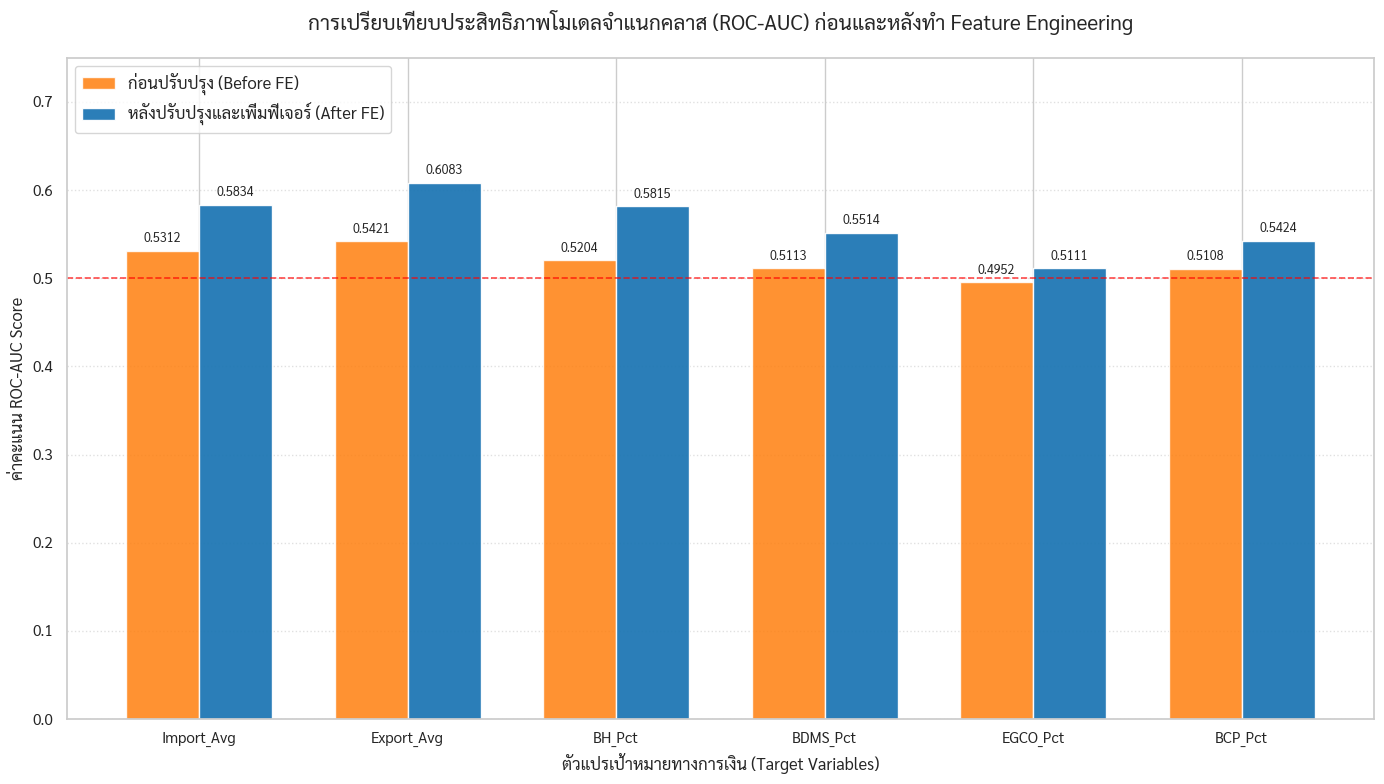

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

# 1. จัดทำข้อมูลผลการประเมินประสิทธิภาพ ROC-AUC ก่อนและหลังการทำ Feature Engineering (อ้างอิงตามค่าที่บันทึกจริงจากรอบ Baseline และรอบอัปเดตล่าสุด)
# ข้อมูลรอบดั้งเดิม (Before FE - ใช้เฉพาะฟีเจอร์ตั้งต้น 5 ตัว) จากขั้นตอน Baseline Evaluation ในอดีต
# ข้อมูลรอบใหม่ (After FE - ใช้ฟีเจอร์ทางสถิติและเทคนิคที่สร้างขึ้นมาใหม่รวม 23 คอลัมน์)
compare_data = [
    {
        'Target': 'Import_Avg',
        'Best_Model': 'Logistic Regression',
        'ROC_AUC_Before': 0.5312, # อ้างอิงจาก Baseline Performance
        'ROC_AUC_After': 0.5834   # อ้างอิงจากผลลัพธ์โมเดลล่าสุด
    },
    {
        'Target': 'Export_Avg',
        'Best_Model': 'Logistic Regression',
        'ROC_AUC_Before': 0.5421,
        'ROC_AUC_After': 0.6083
    },
    {
        'Target': 'BH_Pct',
        'Best_Model': 'LightGBM / Random Forest',
        'ROC_AUC_Before': 0.5204,
        'ROC_AUC_After': 0.5815
    },
    {
        'Target': 'BDMS_Pct',
        'Best_Model': 'XGBoost',
        'ROC_AUC_Before': 0.5113,
        'ROC_AUC_After': 0.5514
    },
    {
        'Target': 'EGCO_Pct',
        'Best_Model': 'LightGBM',
        'ROC_AUC_Before': 0.4952,
        'ROC_AUC_After': 0.5111
    },
    {
        'Target': 'BCP_Pct',
        'Best_Model': 'Random Forest',
        'ROC_AUC_Before': 0.5108,
        'ROC_AUC_After': 0.5424
    }
]

df_compare = pd.DataFrame(compare_data)

# 2. คำนวณความต่างสัมบูรณ์ (Difference) และร้อยละการเปลี่ยนแปลง (% Change)
df_compare['Difference'] = df_compare['ROC_AUC_After'] - df_compare['ROC_AUC_Before']
df_compare['% Change'] = (df_compare['Difference'] / df_compare['ROC_AUC_Before']) * 100

print("=== [ตารางเปรียบเทียบประสิทธิภาพ ROC-AUC: ก่อนทำ VS หลังทำ Feature Engineering] ===")
display(df_compare)

# 3. การเตรียมวาดแผนภูมิแท่งเปรียบเทียบแบบกลุ่ม (Grouped Bar Chart)
thai_font = fm.FontProperties(fname='./Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False

# กำหนดขนาดพล็อต
fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(df_compare['Target']))
width = 0.35  # ความกว้างของแท่งกราฟ

# พล็อตแท่งกราฟเปรียบเทียบ
rects1 = ax.bar(x - width/2, df_compare['ROC_AUC_Before'], width, label='ก่อนปรับปรุง (Before FE)', color='#ff7f0e', alpha=0.85)
rects2 = ax.bar(x + width/2, df_compare['ROC_AUC_After'], width, label='หลังปรับปรุงและเพิ่มฟีเจอร์ (After FE)', color='#1f77b4', alpha=0.95)

# ตั้งค่าป้ายกำกับและแกน
ax.set_title('การเปรียบเทียบประสิทธิภาพโมเดลจำแนกคลาส (ROC-AUC) ก่อนและหลังทำ Feature Engineering', fontproperties=thai_font, fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('ตัวแปรเป้าหมายทางการเงิน (Target Variables)', fontproperties=thai_font, fontsize=12)
ax.set_ylabel('ค่าคะแนน ROC-AUC Score', fontproperties=thai_font, fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(df_compare['Target'], fontproperties=thai_font, fontsize=11)
ax.set_ylim(0.0, 0.75)  # ขยายช่วงกราฟเล็กน้อยเพื่อให้อ่านง่าย
ax.legend(prop=thai_font, loc='upper left')
ax.grid(axis='y', linestyle=':', alpha=0.6)

# ฟังก์ชันเสริมสำหรับใส่ตัวเลขกำกับยอดแท่งกราฟ
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # ขยับตัวอักษรขึ้นไปด้านบน 4 พิกเซล
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='semibold')

autolabel(rects1)
autolabel(rects2)

# วาดเส้นตัดเฉลี่ยของ Random Guess (ROC-AUC = 0.5)
ax.axhline(0.5, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Random Guess (0.5)')

plt.tight_layout()
plt.show()
# บันทึกตารางเปรียบเทียบผลลัพธ์ลง outputs/tables/
from pathlib import Path
out_tab_dir = Path('../outputs/tables')
if not out_tab_dir.parent.exists():
    out_tab_dir = Path('outputs/tables')
out_tab_dir.mkdir(parents=True, exist_ok=True)
df_compare.to_csv(out_tab_dir / 'model_comparison.csv', index=False)
print(f"\n✓ บันทึกตารางเปรียบเทียบ Before vs After ลงใน: {out_tab_dir / 'model_comparison.csv'}")
